# Modelo de Clasificación Multi-clase: 3 Clases

Este notebook entrena un modelo de clasificación usando **3 clases clínicas**:
- `bajo` → Precision < 35
- `medio` → 35 ≤ Precision < 60
- `alto` → Precision ≥ 60

Se comparan múltiples algoritmos y se selecciona el mejor basado en validación.

In [1]:
# Importar bibliotecas y configuración
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

DATA_PATH = Path('archivos_neuroflex/neuroflex_dataset_augmented.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('neuroflex_dataset_augmented.csv')

print('Configuración inicial lista.')
print('Notebook: Modelo de 3 Clases')

Configuración inicial lista.
Notebook: Modelo de 3 Clases


In [2]:
# Cargar y explorar el dataset
df = pd.read_csv(DATA_PATH)
df = df.drop(columns=['name', 'rut'], errors='ignore')
if 'source_session_id' not in df.columns:
    raise ValueError('El dataset debe incluir source_session_id para separar por sesión.')
df['source_session_id'] = df['source_session_id'].fillna('').astype(str)
if df['source_session_id'].eq('').any():
    raise ValueError('Faltan identificadores de sesión de origen para separar los conjuntos.')
hand_map = {'right': 1, 'left': 2, 'ambidextrous': 3, '1': 1, '2': 2, '3': 3, '1.0': 1, '2.0': 2, '3.0': 3}
df['dominant_hand'] = (
    df['dominant_hand'].astype('string').str.strip().str.lower().map(hand_map).astype('Int64')
)
print(f'Forma del dataset: {df.shape}')
print('\nColumnas disponibles:')
print(df.columns.tolist()[:10], '... total:', len(df.columns))

# Limpiar datos
if 'Precision' in df.columns:
    df['Precision'] = pd.to_numeric(df['Precision'], errors='coerce').clip(lower=0, upper=100)

print('\nValores nulos por columna:')
null_counts = df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False)
if len(null_counts) > 0:
    print(null_counts)
else:
    print('No hay valores nulos')

Forma del dataset: (6000, 13)

Columnas disponibles:
['dominant_hand', 'TiempoRespuestaPararse', 'Precision', 'TiempoActivoTarea', 'CantAciertasTotales', 'ObjetosInteractuadosCorrectamente', 'TiempoRespuestaPregunta1', 'TiempoRespuestaPregunta2', 'TiempoRespuestaPregunta3', 'TiempoCapturarNumero'] ... total: 13

Valores nulos por columna:
dominant_hand    53
dtype: int64


Distribución de la variable objetivo (3 clases):
target
0   0.5842
1   0.2450
2   0.1708
Name: proportion, dtype: float64

Cuentas absolutas:
target
0    3505
1    1470
2    1025
Name: count, dtype: int64


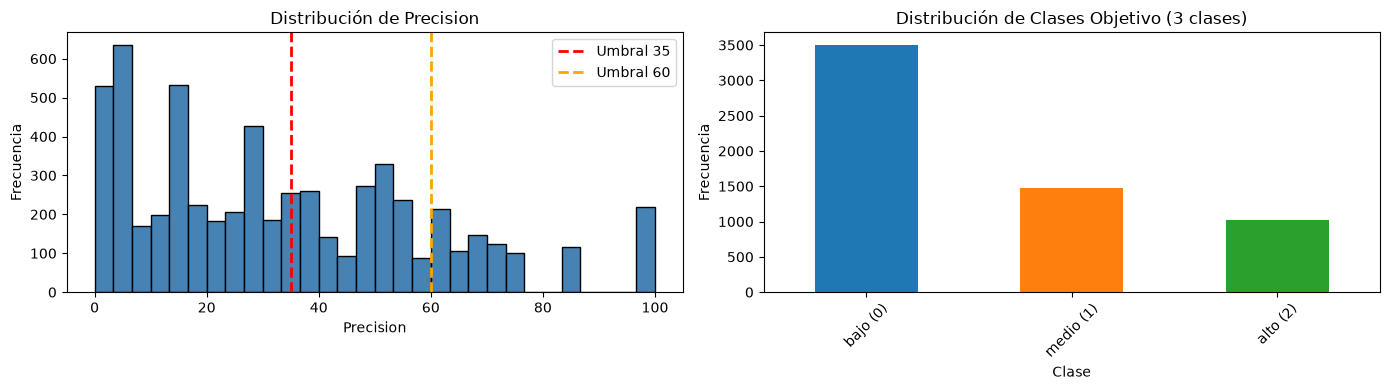

In [3]:
# Crear variable objetivo con 3 clases
df['performance_band'] = pd.cut(
    df['Precision'],
    bins=[-1, 35, 60, 101],
    labels=['bajo', 'medio', 'alto'],
    right=False,
    include_lowest=True,
)
df['target'] = df['performance_band'].map({'bajo': 0, 'medio': 1, 'alto': 2})

print('Distribución de la variable objetivo (3 clases):')
print(df['target'].value_counts(normalize=True).sort_index())
print(f"\nCuentas absolutas:")
print(df['target'].value_counts().sort_index())

# Visualizar distribución
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['Precision'], bins=30, edgecolor='black', color='steelblue')
axes[0].axvline(35, color='red', linestyle='--', linewidth=2, label='Umbral 35')
axes[0].axvline(60, color='orange', linestyle='--', linewidth=2, label='Umbral 60')
axes[0].set_title('Distribución de Precision')
axes[0].set_xlabel('Precision')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

df['target'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e', '#2ca02c'])
axes[1].set_title('Distribución de Clases Objetivo (3 clases)')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Frecuencia')
axes[1].set_xticklabels(['bajo (0)', 'medio (1)', 'alto (2)'], rotation=45)

plt.tight_layout()
plt.show()

In [4]:
# Feature engineering
model_df = df.copy()

# Eliminar columnas irrelevantes
exclude_cols = ['Performance', 'rendimiento', 'performance_band', 'Precision_bin']
model_df = model_df.drop(columns=[c for c in exclude_cols if c in model_df.columns], errors='ignore')

# Crear nuevas características

model_df['tiempo_total'] = (
    model_df.get('TiempoRespuestaPararse', 0) + 
    model_df.get('TiempoActivoTarea', 0) + 
    model_df.get('TiempoTutorial', 0)
)
model_df['ratio_aciertos'] = (
    model_df.get('CantAciertasTotales', 0) / 
    (model_df.get('ObjetosInteractuadosCorrectamente', 0) + 1)
)

# Transformaciones logarítmicas
for col in ['TiempoRespuestaPararse', 'TiempoActivoTarea', 'TiempoTutorial', 
            'TiempoRespuestaPregunta1', 'TiempoRespuestaPregunta2', 'TiempoRespuestaPregunta3']:
    if col in model_df.columns:
        model_df[f'{col}_log'] = np.log1p(model_df[col].clip(lower=0))

# Seleccionar features
feature_cols = [c for c in model_df.columns if c not in ['target', 'performance_band', 'Precision', 'Precision_bin', 'source_session_id', 'FechaObservacion', 'name', 'rut']]
print('Número de features finales:', len(feature_cols))

Número de features finales: 19


In [5]:
# Dividir por sesión de origen para que una sesión no aparezca en más de un conjunto.
X_final = model_df[feature_cols]
y_final = model_df['target']
groups = df.loc[X_final.index, 'source_session_id'].astype(str)


def grouped_split(X, y, groups, test_size, seed):
    """Elige entre particiones por grupo la que mejor conserva la distribución de clases."""
    class_distribution = y.value_counts(normalize=True).sort_index()
    splitter = GroupShuffleSplit(n_splits=200, test_size=test_size, random_state=seed)
    best_split = None
    best_score = float('inf')

    for train_indices, test_indices in splitter.split(X, y, groups):
        test_distribution = y.iloc[test_indices].value_counts(normalize=True).reindex(
            class_distribution.index, fill_value=0
        )
        size_error = abs(len(test_indices) / len(y) - test_size)
        score = (test_distribution - class_distribution).abs().sum() + size_error
        if score < best_score:
            best_score = score
            best_split = (train_indices, test_indices)

    if best_split is None:
        raise ValueError('No fue posible crear una partición agrupada por sesión.')

    train_indices, test_indices = best_split
    return (
        X.iloc[train_indices], X.iloc[test_indices],
        y.iloc[train_indices], y.iloc[test_indices],
        groups.iloc[train_indices], groups.iloc[test_indices],
    )


X_train, X_temp, y_train, y_temp, groups_train, groups_temp = grouped_split(
    X_final, y_final, groups, test_size=0.15, seed=SEED
)
X_train, X_val, y_train, y_val, groups_train, groups_val = grouped_split(
    X_train, y_train, groups_train, test_size=0.15 / 0.85, seed=SEED + 1
)
X_test, y_test = X_temp, y_temp

assert set(groups_train).isdisjoint(groups_val)
assert set(groups_train).isdisjoint(groups_temp)
assert set(groups_val).isdisjoint(groups_temp)

print('Train size:', X_train.shape)
print('Validation size:', X_val.shape)
print('Test size:', X_test.shape)
print('\nDistribución de clases (train):')
print(pd.Series(y_train).value_counts().sort_index())
print('\nDistribución de clases (validation):')
print(pd.Series(y_val).value_counts().sort_index())
print('\nDistribución de clases (test):')
print(pd.Series(y_test).value_counts().sort_index())

Train size: (4172, 19)
Validation size: (920, 19)
Test size: (908, 19)

Distribución de clases (train):
target
0    2441
1    1032
2     699
Name: count, dtype: int64

Distribución de clases (validation):
target
0    528
1    226
2    166
Name: count, dtype: int64

Distribución de clases (test):
target
0    536
1    212
2    160
Name: count, dtype: int64


In [6]:
# Crear preprocesador
categorical_cols = [c for c in X_train.columns if c == 'dominant_hand' or X_train[c].dtype == 'object' or pd.api.types.is_categorical_dtype(X_train[c])]
numeric_cols = [c for c in X_train.columns if c not in categorical_cols and pd.api.types.is_numeric_dtype(X_train[c])]

preprocessor_model = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols),
    ]
)

print('Preprocesador creado.')
print(f'Columnas numéricas: {len(numeric_cols)}')
print(f'Columnas categóricas: {len(categorical_cols)}')

Preprocesador creado.
Columnas numéricas: 18
Columnas categóricas: 1


In [7]:
# Entrenar múltiples modelos y compararlos
models = {
    'LogisticRegression': LogisticRegression(max_iter=5000, class_weight='balanced', random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=500, random_state=SEED, class_weight='balanced'),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=500, random_state=SEED, class_weight='balanced'),
    'GradientBoosting': GradientBoostingClassifier(random_state=SEED),
    'SVC': SVC(class_weight='balanced', random_state=SEED, probability=True),
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor_model),
        ('model', model),
    ])
    pipe.fit(X_train, y_train)
    val_pred = pipe.predict(X_val)
    
    val_acc = accuracy_score(y_val, val_pred)
    val_prec = precision_score(y_val, val_pred, average='weighted', zero_division=0)
    val_rec = recall_score(y_val, val_pred, average='weighted', zero_division=0)
    val_f1 = f1_score(y_val, val_pred, average='weighted', zero_division=0)
    
    results.append({
        'model': name,
        'accuracy': val_acc,
        'precision': val_prec,
        'recall': val_rec,
        'f1': val_f1,
    })
    
    print(f'\n=== {name} ===')
    print(f'Accuracy: {val_acc:.4f}')
    print(f'Precision (weighted): {val_prec:.4f}')
    print(f'Recall (weighted): {val_rec:.4f}')
    print(f'F1 (weighted): {val_f1:.4f}')

results_df = pd.DataFrame(results).sort_values('f1', ascending=False)
print('\n' + '='*60)
print('Ranking por F1 en validación:')
print('='*60)
print(results_df)


=== LogisticRegression ===
Accuracy: 0.6609
Precision (weighted): 0.7841
Recall (weighted): 0.6609
F1 (weighted): 0.6680

=== RandomForest ===
Accuracy: 0.7196
Precision (weighted): 0.7189
Recall (weighted): 0.7196
F1 (weighted): 0.6789

=== ExtraTrees ===
Accuracy: 0.6304
Precision (weighted): 0.5303
Recall (weighted): 0.6304
F1 (weighted): 0.5254

=== GradientBoosting ===
Accuracy: 0.5609
Precision (weighted): 0.5554
Recall (weighted): 0.5609
F1 (weighted): 0.5494

=== SVC ===
Accuracy: 0.6478
Precision (weighted): 0.6356
Recall (weighted): 0.6478
F1 (weighted): 0.6411

Ranking por F1 en validación:
                model  accuracy  precision  recall     f1
1        RandomForest    0.7196     0.7189  0.7196 0.6789
0  LogisticRegression    0.6609     0.7841  0.6609 0.6680
4                 SVC    0.6478     0.6356  0.6478 0.6411
3    GradientBoosting    0.5609     0.5554  0.5609 0.5494
2          ExtraTrees    0.6304     0.5303  0.6304 0.5254


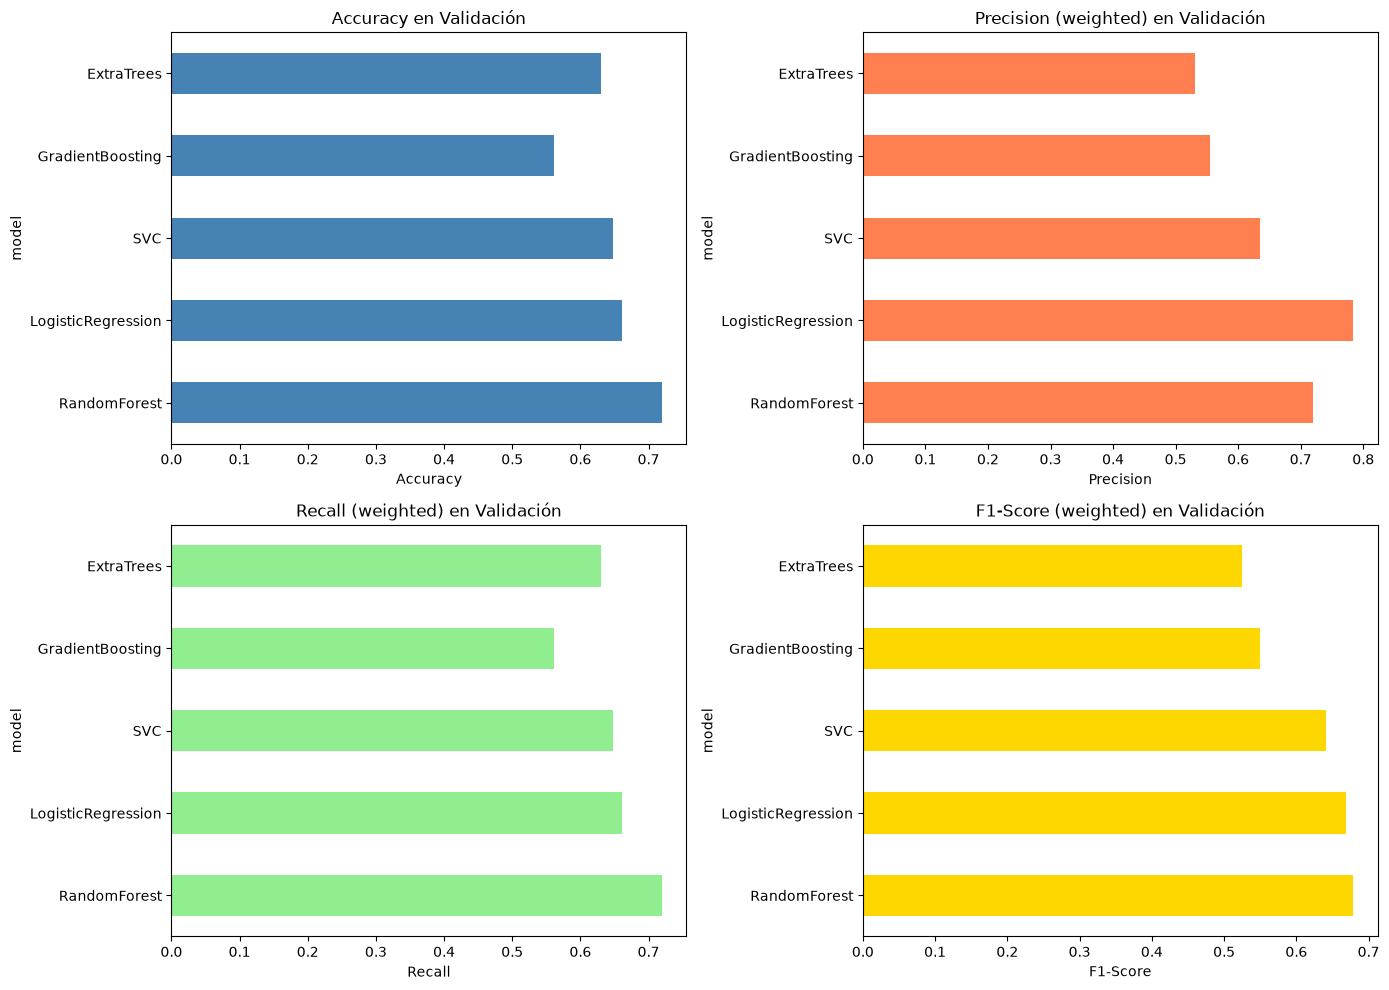

In [8]:
# Visualizar comparación de modelos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

results_df.plot(x='model', y='accuracy', kind='barh', ax=axes[0, 0], color='steelblue', legend=False)
axes[0, 0].set_title('Accuracy en Validación')
axes[0, 0].set_xlabel('Accuracy')

results_df.plot(x='model', y='precision', kind='barh', ax=axes[0, 1], color='coral', legend=False)
axes[0, 1].set_title('Precision (weighted) en Validación')
axes[0, 1].set_xlabel('Precision')

results_df.plot(x='model', y='recall', kind='barh', ax=axes[1, 0], color='lightgreen', legend=False)
axes[1, 0].set_title('Recall (weighted) en Validación')
axes[1, 0].set_xlabel('Recall')

results_df.plot(x='model', y='f1', kind='barh', ax=axes[1, 1], color='gold', legend=False)
axes[1, 1].set_title('F1-Score (weighted) en Validación')
axes[1, 1].set_xlabel('F1-Score')

plt.tight_layout()
plt.show()

In [9]:
# Evaluar el mejor modelo en test
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    
    print(f'\n{"="*60}')
    print(f'EVALUACIÓN FINAL EN TEST: {model_name}')
    print(f'{"="*60}')
    print(f'Accuracy: {acc:.4f}')
    print(f'Precision (weighted): {precision:.4f}')
    print(f'Recall (weighted): {recall:.4f}')
    print(f'F1-Score (weighted): {f1:.4f}')
    print('\nMatriz de Confusión:')
    print(cm)
    
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix': cm,
        'y_pred': y_pred,
    }

# Seleccionar y evaluar el mejor modelo
best_model_name = results_df.iloc[0]['model']
best_model = models[best_model_name]

best_pipe = Pipeline([
    ('preprocessor', preprocessor_model),
    ('model', best_model),
])

print(f'\n✓ Modelo seleccionado: {best_model_name}')
final_metrics = evaluate_model(best_pipe, X_train, y_train, X_test, y_test, best_model_name)


✓ Modelo seleccionado: RandomForest

EVALUACIÓN FINAL EN TEST: RandomForest
Accuracy: 0.5452
Precision (weighted): 0.5375
Recall (weighted): 0.5452
F1-Score (weighted): 0.5412

Matriz de Confusión:
[[398 104  34]
 [ 95  49  68]
 [ 59  53  48]]


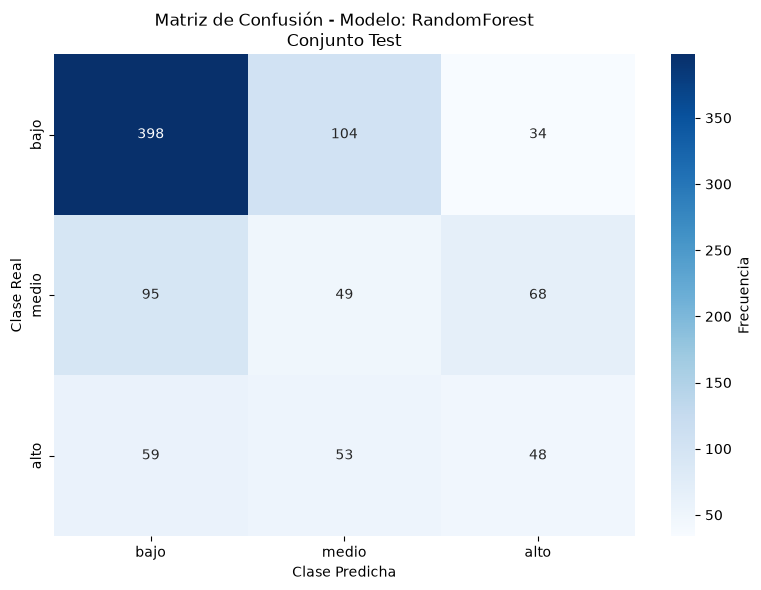


REPORTE DETALLADO DE CLASIFICACIÓN
              precision    recall  f1-score   support

        bajo     0.7210    0.7425    0.7316       536
       medio     0.2379    0.2311    0.2344       212
        alto     0.3200    0.3000    0.3097       160

    accuracy                         0.5452       908
   macro avg     0.4263    0.4246    0.4252       908
weighted avg     0.5375    0.5452    0.5412       908



In [10]:
# Visualizar matriz de confusión y reporte detallado
y_test_pred = final_metrics['y_pred']
cm = final_metrics['confusion_matrix']

# Matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['bajo', 'medio', 'alto'],
            yticklabels=['bajo', 'medio', 'alto'],
            cbar_kws={'label': 'Frecuencia'})
plt.title(f'Matriz de Confusión - Modelo: {best_model_name}\nConjunto Test')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

# Reporte de clasificación detallado
print('\n' + '='*60)
print('REPORTE DETALLADO DE CLASIFICACIÓN')
print('='*60)
print(classification_report(y_test, y_test_pred, 
                          target_names=['bajo', 'medio', 'alto'],
                          digits=4))

## Conclusiones

**Modelo de 3 Clases Clínicas:**
- Permite capturar más nuances en el rendimiento cognitivo
- Proporciona información clínica más detallada
- Puede tener accuracy ligeramente más bajo que una clasificación binaria (debido a la complejidad)
- Es más útil si se necesita diferenciar entre rendimiento bajo, medio y alto

**Thresholds utilizados:**
- `bajo` → Precision < 35
- `medio` → 35 ≤ Precision < 60  
- `alto` → Precision ≥ 60

Compara este modelo con el de 2 clases en el notebook `neuroflex_comparison_2vs3classes.ipynb` para entender las trade-offs.

## Conclusiones

**Modelo de 3 Clases Clínicas:**
- Permite capturar más nuances en el rendimiento cognitivo
- Proporciona información clínica más detallada
- Puede tener accuracy ligeramente más bajo que una clasificación binaria (debido a la complejidad)
- Es más útil si se necesita diferenciar entre rendimiento bajo, medio y alto

**Thresholds utilizados:**
- `bajo` → Precision < 35
- `medio` → 35 ≤ Precision < 60  
- `alto` → Precision ≥ 60

Compara este modelo con el de 2 clases en el notebook `neuroflex_comparison_2vs3classes.ipynb` para entender las trade-offs.

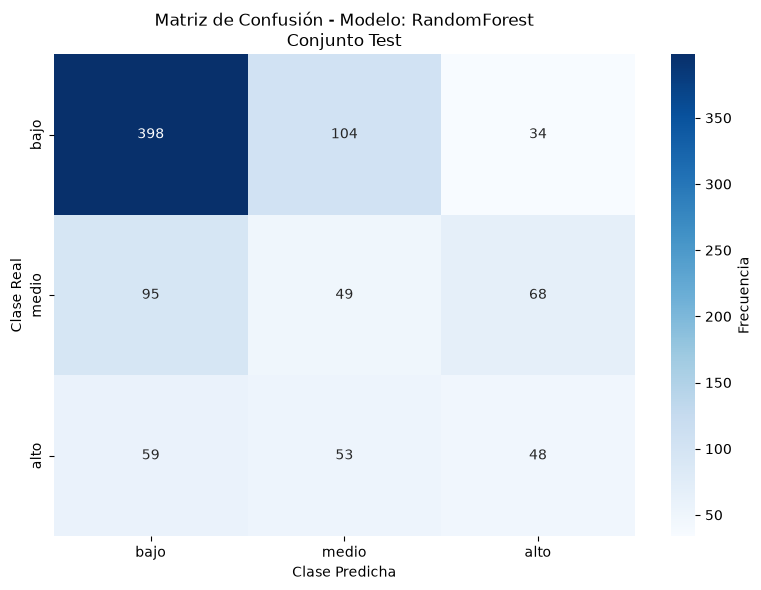


REPORTE DETALLADO DE CLASIFICACIÓN
              precision    recall  f1-score   support

        bajo     0.7210    0.7425    0.7316       536
       medio     0.2379    0.2311    0.2344       212
        alto     0.3200    0.3000    0.3097       160

    accuracy                         0.5452       908
   macro avg     0.4263    0.4246    0.4252       908
weighted avg     0.5375    0.5452    0.5412       908



In [11]:
# Visualizar matriz de confusión y reporte detallado
y_test_pred = final_metrics['y_pred']
cm = final_metrics['confusion_matrix']

# Matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['bajo', 'medio', 'alto'],
            yticklabels=['bajo', 'medio', 'alto'],
            cbar_kws={'label': 'Frecuencia'})
plt.title(f'Matriz de Confusión - Modelo: {best_model_name}\nConjunto Test')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

# Reporte de clasificación detallado
print('\n' + '='*60)
print('REPORTE DETALLADO DE CLASIFICACIÓN')
print('='*60)
print(classification_report(y_test, y_test_pred, 
                          target_names=['bajo', 'medio', 'alto'],
                          digits=4))

In [12]:
# Evaluar el mejor modelo en test
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    
    print(f'\n{"="*60}')
    print(f'EVALUACIÓN FINAL EN TEST: {model_name}')
    print(f'{"="*60}')
    print(f'Accuracy: {acc:.4f}')
    print(f'Precision (weighted): {precision:.4f}')
    print(f'Recall (weighted): {recall:.4f}')
    print(f'F1-Score (weighted): {f1:.4f}')
    print('\nMatriz de Confusión:')
    print(cm)
    
    return {
        'accuracy': acc,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix': cm,
        'y_pred': y_pred,
    }

# Seleccionar y evaluar el mejor modelo
best_model_name = results_df.iloc[0]['model']
best_model = models[best_model_name]

best_pipe = Pipeline([
    ('preprocessor', preprocessor_model),
    ('model', best_model),
])

print(f'\n✓ Modelo seleccionado: {best_model_name}')
final_metrics = evaluate_model(best_pipe, X_train, y_train, X_test, y_test, best_model_name)


✓ Modelo seleccionado: RandomForest

EVALUACIÓN FINAL EN TEST: RandomForest
Accuracy: 0.5452
Precision (weighted): 0.5375
Recall (weighted): 0.5452
F1-Score (weighted): 0.5412

Matriz de Confusión:
[[398 104  34]
 [ 95  49  68]
 [ 59  53  48]]


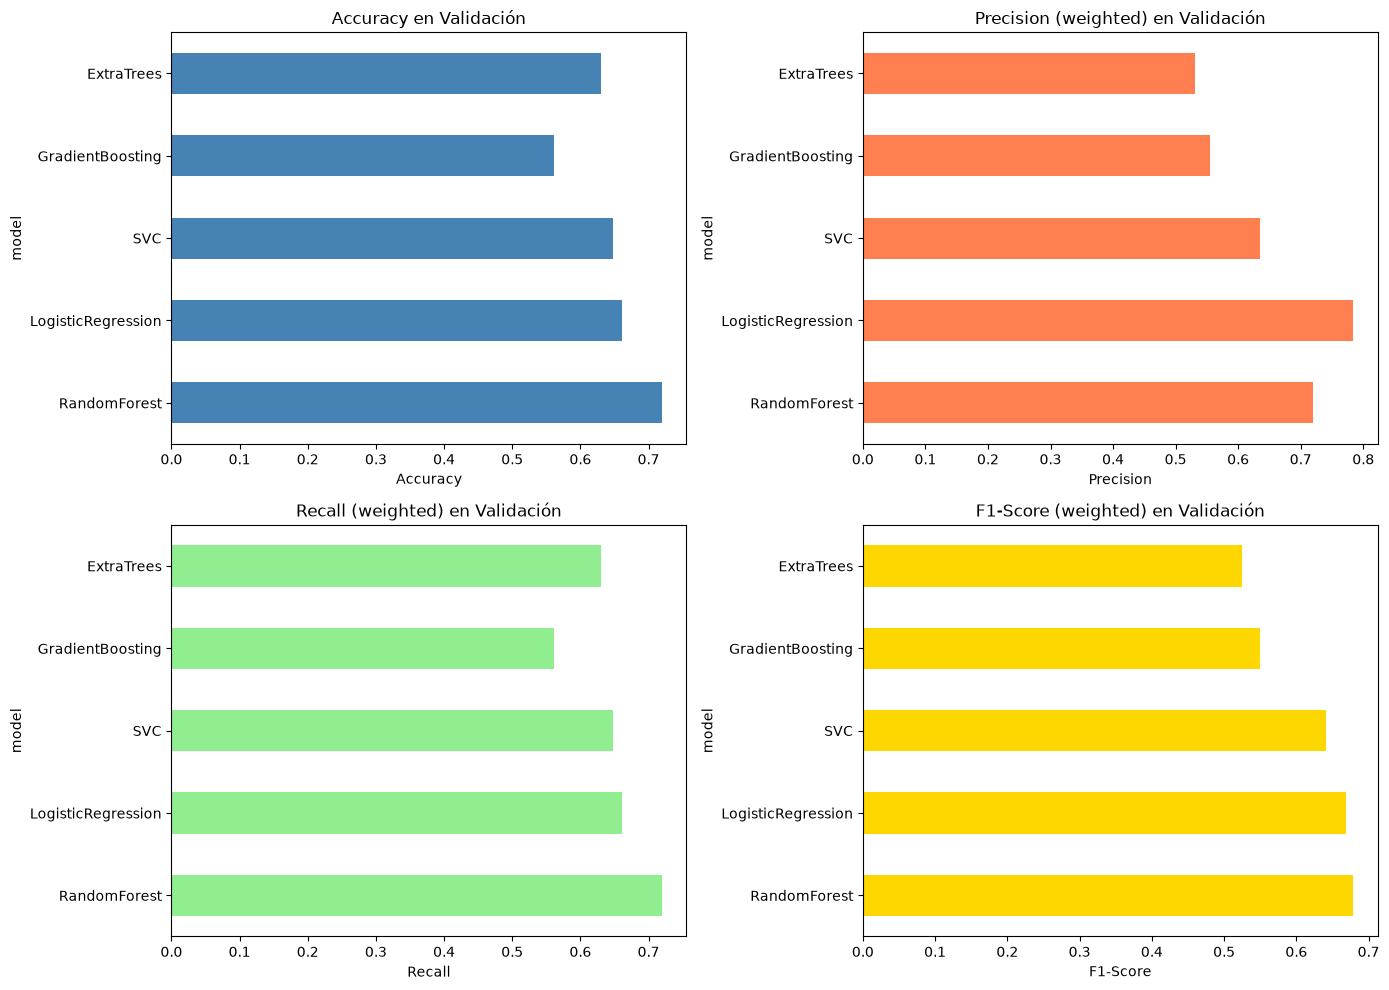

In [13]:
# Visualizar comparación de modelos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

results_df.plot(x='model', y='accuracy', kind='barh', ax=axes[0, 0], color='steelblue', legend=False)
axes[0, 0].set_title('Accuracy en Validación')
axes[0, 0].set_xlabel('Accuracy')

results_df.plot(x='model', y='precision', kind='barh', ax=axes[0, 1], color='coral', legend=False)
axes[0, 1].set_title('Precision (weighted) en Validación')
axes[0, 1].set_xlabel('Precision')

results_df.plot(x='model', y='recall', kind='barh', ax=axes[1, 0], color='lightgreen', legend=False)
axes[1, 0].set_title('Recall (weighted) en Validación')
axes[1, 0].set_xlabel('Recall')

results_df.plot(x='model', y='f1', kind='barh', ax=axes[1, 1], color='gold', legend=False)
axes[1, 1].set_title('F1-Score (weighted) en Validación')
axes[1, 1].set_xlabel('F1-Score')

plt.tight_layout()
plt.show()

In [14]:
# Entrenar múltiples modelos y compararlos
models = {
    'LogisticRegression': LogisticRegression(max_iter=5000, class_weight='balanced', random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=500, random_state=SEED, class_weight='balanced'),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=500, random_state=SEED, class_weight='balanced'),
    'GradientBoosting': GradientBoostingClassifier(random_state=SEED),
    'SVC': SVC(class_weight='balanced', random_state=SEED, probability=True),
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor_model),
        ('model', model),
    ])
    pipe.fit(X_train, y_train)
    val_pred = pipe.predict(X_val)
    
    val_acc = accuracy_score(y_val, val_pred)
    val_prec = precision_score(y_val, val_pred, average='weighted', zero_division=0)
    val_rec = recall_score(y_val, val_pred, average='weighted', zero_division=0)
    val_f1 = f1_score(y_val, val_pred, average='weighted', zero_division=0)
    
    results.append({
        'model': name,
        'accuracy': val_acc,
        'precision': val_prec,
        'recall': val_rec,
        'f1': val_f1,
    })
    
    print(f'\n=== {name} ===')
    print(f'Accuracy: {val_acc:.4f}')
    print(f'Precision (weighted): {val_prec:.4f}')
    print(f'Recall (weighted): {val_rec:.4f}')
    print(f'F1 (weighted): {val_f1:.4f}')

results_df = pd.DataFrame(results).sort_values('f1', ascending=False)
print('\n' + '='*60)
print('Ranking por F1 en validación:')
print('='*60)
print(results_df)


=== LogisticRegression ===
Accuracy: 0.6609
Precision (weighted): 0.7841
Recall (weighted): 0.6609
F1 (weighted): 0.6680

=== RandomForest ===
Accuracy: 0.7196
Precision (weighted): 0.7189
Recall (weighted): 0.7196
F1 (weighted): 0.6789

=== ExtraTrees ===
Accuracy: 0.6304
Precision (weighted): 0.5303
Recall (weighted): 0.6304
F1 (weighted): 0.5254

=== GradientBoosting ===
Accuracy: 0.5609
Precision (weighted): 0.5554
Recall (weighted): 0.5609
F1 (weighted): 0.5494

=== SVC ===
Accuracy: 0.6478
Precision (weighted): 0.6356
Recall (weighted): 0.6478
F1 (weighted): 0.6411

Ranking por F1 en validación:
                model  accuracy  precision  recall     f1
1        RandomForest    0.7196     0.7189  0.7196 0.6789
0  LogisticRegression    0.6609     0.7841  0.6609 0.6680
4                 SVC    0.6478     0.6356  0.6478 0.6411
3    GradientBoosting    0.5609     0.5554  0.5609 0.5494
2          ExtraTrees    0.6304     0.5303  0.6304 0.5254


In [15]:
# Crear preprocesador
categorical_cols = [c for c in X_train.columns if c == 'dominant_hand' or X_train[c].dtype == 'object' or pd.api.types.is_categorical_dtype(X_train[c])]
numeric_cols = [c for c in X_train.columns if c not in categorical_cols and pd.api.types.is_numeric_dtype(X_train[c])]

preprocessor_model = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical_cols),
    ]
)

print('Preprocesador creado.')
print(f'Columnas numéricas: {len(numeric_cols)}')
print(f'Columnas categóricas: {len(categorical_cols)}')

Preprocesador creado.
Columnas numéricas: 18
Columnas categóricas: 1


In [16]:
# Dividir por sesión de origen para que una sesión no aparezca en más de un conjunto.
X_final = model_df[feature_cols]
y_final = model_df['target']
groups = df.loc[X_final.index, 'source_session_id'].astype(str)


def grouped_split(X, y, groups, test_size, seed):
    """Elige entre particiones por grupo la que mejor conserva la distribución de clases."""
    class_distribution = y.value_counts(normalize=True).sort_index()
    splitter = GroupShuffleSplit(n_splits=200, test_size=test_size, random_state=seed)
    best_split = None
    best_score = float('inf')

    for train_indices, test_indices in splitter.split(X, y, groups):
        test_distribution = y.iloc[test_indices].value_counts(normalize=True).reindex(
            class_distribution.index, fill_value=0
        )
        size_error = abs(len(test_indices) / len(y) - test_size)
        score = (test_distribution - class_distribution).abs().sum() + size_error
        if score < best_score:
            best_score = score
            best_split = (train_indices, test_indices)

    if best_split is None:
        raise ValueError('No fue posible crear una partición agrupada por sesión.')

    train_indices, test_indices = best_split
    return (
        X.iloc[train_indices], X.iloc[test_indices],
        y.iloc[train_indices], y.iloc[test_indices],
        groups.iloc[train_indices], groups.iloc[test_indices],
    )


X_train, X_temp, y_train, y_temp, groups_train, groups_temp = grouped_split(
    X_final, y_final, groups, test_size=0.15, seed=SEED
)
X_train, X_val, y_train, y_val, groups_train, groups_val = grouped_split(
    X_train, y_train, groups_train, test_size=0.15 / 0.85, seed=SEED + 1
)
X_test, y_test = X_temp, y_temp

assert set(groups_train).isdisjoint(groups_val)
assert set(groups_train).isdisjoint(groups_temp)
assert set(groups_val).isdisjoint(groups_temp)

print('Train size:', X_train.shape)
print('Validation size:', X_val.shape)
print('Test size:', X_test.shape)
print('\nDistribución de clases (train):')
print(pd.Series(y_train).value_counts().sort_index())
print('\nDistribución de clases (validation):')
print(pd.Series(y_val).value_counts().sort_index())
print('\nDistribución de clases (test):')
print(pd.Series(y_test).value_counts().sort_index())

Train size: (4172, 19)
Validation size: (920, 19)
Test size: (908, 19)

Distribución de clases (train):
target
0    2441
1    1032
2     699
Name: count, dtype: int64

Distribución de clases (validation):
target
0    528
1    226
2    166
Name: count, dtype: int64

Distribución de clases (test):
target
0    536
1    212
2    160
Name: count, dtype: int64


In [17]:
# Feature engineering
model_df = df.copy()

# Eliminar columnas irrelevantes
exclude_cols = ['Performance', 'rendimiento', 'performance_band', 'Precision_bin']
model_df = model_df.drop(columns=[c for c in exclude_cols if c in model_df.columns], errors='ignore')

# Crear nuevas características

model_df['tiempo_total'] = (
    model_df.get('TiempoRespuestaPararse', 0) + 
    model_df.get('TiempoActivoTarea', 0) + 
    model_df.get('TiempoTutorial', 0)
)
model_df['ratio_aciertos'] = (
    model_df.get('CantAciertasTotales', 0) / 
    (model_df.get('ObjetosInteractuadosCorrectamente', 0) + 1)
)

# Transformaciones logarítmicas
for col in ['TiempoRespuestaPararse', 'TiempoActivoTarea', 'TiempoTutorial', 
            'TiempoRespuestaPregunta1', 'TiempoRespuestaPregunta2', 'TiempoRespuestaPregunta3']:
    if col in model_df.columns:
        model_df[f'{col}_log'] = np.log1p(model_df[col].clip(lower=0))

# Seleccionar features
feature_cols = [c for c in model_df.columns if c not in ['target', 'performance_band', 'Precision', 'Precision_bin', 'source_session_id', 'FechaObservacion', 'name', 'rut']]
print('Número de features finales:', len(feature_cols))

Número de features finales: 19


Distribución de la variable objetivo (3 clases):
target
0   0.5842
1   0.2450
2   0.1708
Name: proportion, dtype: float64

Cuentas absolutas:
target
0    3505
1    1470
2    1025
Name: count, dtype: int64


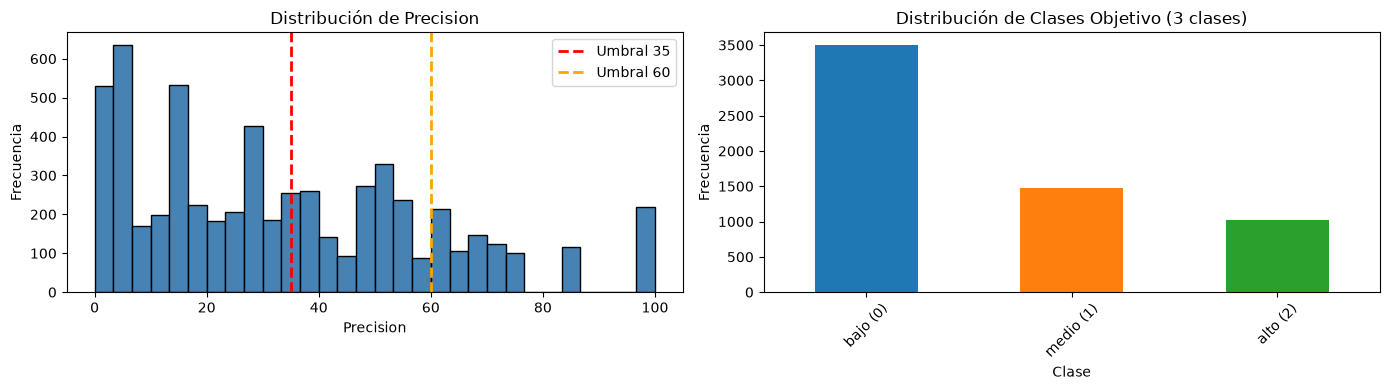

In [18]:
# Crear variable objetivo con 3 clases
df['performance_band'] = pd.cut(
    df['Precision'],
    bins=[-1, 35, 60, 101],
    labels=['bajo', 'medio', 'alto'],
    right=False,
    include_lowest=True,
)
df['target'] = df['performance_band'].map({'bajo': 0, 'medio': 1, 'alto': 2})

print('Distribución de la variable objetivo (3 clases):')
print(df['target'].value_counts(normalize=True).sort_index())
print(f"\nCuentas absolutas:")
print(df['target'].value_counts().sort_index())

# Visualizar distribución
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['Precision'], bins=30, edgecolor='black', color='steelblue')
axes[0].axvline(35, color='red', linestyle='--', linewidth=2, label='Umbral 35')
axes[0].axvline(60, color='orange', linestyle='--', linewidth=2, label='Umbral 60')
axes[0].set_title('Distribución de Precision')
axes[0].set_xlabel('Precision')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

df['target'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e', '#2ca02c'])
axes[1].set_title('Distribución de Clases Objetivo (3 clases)')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Frecuencia')
axes[1].set_xticklabels(['bajo (0)', 'medio (1)', 'alto (2)'], rotation=45)

plt.tight_layout()
plt.show()

In [19]:
# Cargar y explorar el dataset
df = pd.read_csv(DATA_PATH)
df = df.drop(columns=['name', 'rut'], errors='ignore')
if 'source_session_id' not in df.columns:
    raise ValueError('El dataset debe incluir source_session_id para separar por sesión.')
df['source_session_id'] = df['source_session_id'].fillna('').astype(str)
if df['source_session_id'].eq('').any():
    raise ValueError('Faltan identificadores de sesión de origen para separar los conjuntos.')
hand_map = {'right': 1, 'left': 2, 'ambidextrous': 3, '1': 1, '2': 2, '3': 3, '1.0': 1, '2.0': 2, '3.0': 3}
df['dominant_hand'] = (
    df['dominant_hand'].astype('string').str.strip().str.lower().map(hand_map).astype('Int64')
)
print(f'Forma del dataset: {df.shape}')
print('\nColumnas disponibles:')
print(df.columns.tolist()[:10], '... total:', len(df.columns))

# Limpiar datos
if 'Precision' in df.columns:
    df['Precision'] = pd.to_numeric(df['Precision'], errors='coerce').clip(lower=0, upper=100)

print('\nValores nulos por columna:')
null_counts = df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False)
if len(null_counts) > 0:
    print(null_counts)
else:
    print('No hay valores nulos')

Forma del dataset: (6000, 13)

Columnas disponibles:
['dominant_hand', 'TiempoRespuestaPararse', 'Precision', 'TiempoActivoTarea', 'CantAciertasTotales', 'ObjetosInteractuadosCorrectamente', 'TiempoRespuestaPregunta1', 'TiempoRespuestaPregunta2', 'TiempoRespuestaPregunta3', 'TiempoCapturarNumero'] ... total: 13

Valores nulos por columna:
dominant_hand    53
dtype: int64


In [20]:
# Importar bibliotecas y configuración
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

DATA_PATH = Path('archivos_neuroflex/neuroflex_dataset_augmented.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('neuroflex_dataset_augmented.csv')

print('Configuración inicial lista.')
print('Notebook: Modelo de 3 Clases')

Configuración inicial lista.
Notebook: Modelo de 3 Clases


# Modelo de Clasificación Multi-clase: 3 Clases

Este notebook entrena un modelo de clasificación usando **3 clases clínicas**:
- `bajo` → Precision < 35
- `medio` → 35 ≤ Precision < 60
- `alto` → Precision ≥ 60

Se comparan múltiples algoritmos y se selecciona el mejor basado en validación.

## Exportar pipeline final a ONNX

Ejecuta esta celda después de entrenar el modelo final. El archivo resultante incluye el preprocesamiento de scikit-learn y el clasificador. La entrada son las 19 columnas de `feature_cols` ya transformadas por el bloque de *feature engineering* de este notebook.


In [21]:
from pathlib import Path
import onnx
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType, Int64TensorType

# best_pipe debe haberse ajustado en la evaluación final.
if not hasattr(best_pipe, "classes_") and not hasattr(best_pipe.named_steps["model"], "classes_"):
    raise RuntimeError("Ejecuta primero la celda de evaluación final para entrenar best_pipe.")

# Declarar cada columna como una entrada ONNX independiente.
initial_types = []
for column in X_train.columns:
    if column in categorical_cols and pd.api.types.is_integer_dtype(X_train[column].dtype):
        tensor_type = Int64TensorType([None, 1])
    else:
        tensor_type = FloatTensorType([None, 1])
    initial_types.append((column, tensor_type))

onnx_model = convert_sklearn(
    best_pipe,
    initial_types=initial_types,
    target_opset=17,
    options={id(best_pipe.named_steps["model"]): {"zipmap": False}},
)
onnx.checker.check_model(onnx_model)
output_path = DATA_PATH.parent / "neuroflex_3classes_model.onnx"
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_bytes(onnx_model.SerializeToString())
print(f"Modelo ONNX guardado en: {output_path.resolve()}")
classes = list(best_pipe.named_steps["model"].classes_)
print(f"Entradas: {len(initial_types)} columnas | clases: {classes}")


Modelo ONNX guardado en: C:\Users\cristobal\Downloads\NeuroflexW-main\archivos_neuroflex\neuroflex_3classes_model.onnx
Entradas: 19 columnas | clases: [np.int64(0), np.int64(1), np.int64(2)]
